____
__Universidad Tecnológica Nacional, Buenos Aires__<br/>
__Ingeniería Industrial__<br/>
__Cátedra de Ciencia de Datos - Curso I5521__<br/>
__Trabajo Práctico Final - Alumno: Rodrigo Alejandro Muñoz Vera__
____
# TP Final - Telco Churn
# Preprocesamiento (manipulación de los datos)

**¿Qué hacemos acá y qué dejamos para el pipeline?** Hay que tener cuidado con el **data leakage** (que información del test se filtre al entrenamiento):
- Acá solo hacemos cosas que se calculan **cliente por cliente**, mirando únicamente sus propios datos: corregir tipos y aplicar reglas lógicas. Esto no "aprende" nada del resto de los datos, así que se puede hacer antes de separar train y test.
- En cambio, imputar con la mediana o la moda, estandarizar o hacer PCA **aprenden algo de todo el conjunto** (una mediana, una media...). Eso lo hacemos dentro del `Pipeline` en el notebook de machine learning, para que se ajuste solo con train.

## Paso 1: Cargamos los datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
sns.set_theme(style='whitegrid')
os.makedirs('figuras', exist_ok=True)

df = pd.read_csv('telco_churn_clusterai.csv')
print(df.shape)

# guardamos cuántos faltantes había al principio para comparar al final
faltantes_antes = df.isna().sum()
completas_antes = (df.isna().sum(axis=1) == 0).sum()
print('Faltantes totales al inicio:', faltantes_antes.sum())

(7043, 22)
Faltantes totales al inicio: 13948


## Paso 2: Corregimos la estructura y los tipos de datos

En el EDA encontramos tres problemas: una columna que sobra, `TotalCharges` guardada como texto y `SeniorCitizen` en un formato distinto a las demás variables binarias.

In [2]:
# 2.1 Sacamos la columna del índice que quedó al exportar el CSV (no es un dato del cliente)
df = df.drop(columns=['Unnamed: 0'])

# 2.2 TotalCharges: los ' ' son clientes nuevos (tenure 0) que todavía no pagaron nada -> les ponemos 0
blancos = df['TotalCharges'].str.strip() == ''
print('Blancos en TotalCharges:', blancos.sum())
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.loc[blancos, 'TotalCharges'] = 0

# 2.3 El target lo pasamos a 0/1 (1 = se fue). Ponemos como clase positiva la que queremos detectar
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# 2.4 SeniorCitizen la pasamos a 'Yes'/'No' para tratarla igual que las otras binarias (los NaN quedan NaN)
df['SeniorCitizen'] = df['SeniorCitizen'].map({1.0: 'Yes', 0.0: 'No'})

df.dtypes

Blancos en TotalCharges: 11


customerID              str
gender                  str
SeniorCitizen           str
Partner                 str
Dependents              str
tenure              float64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

**Conclusión:** ahora las 3 variables numéricas son `float`, el target es 0/1 y todas las categóricas son texto.

## Paso 3: Imputación con reglas lógicas

Hay variables que dependen de otras, así que podemos deducir el dato que falta **con certeza** en lugar de rellenarlo con el promedio o la moda. Es mejor porque:
- Si imputamos con la moda, a todos los clientes con NaN les ponemos el valor "típico", aunque no sea el suyo. Eso mete ruido.
- Las reglas solo usan datos del mismo cliente, así que no hay data leakage.

Para cada regla contamos cuántos valores recuperamos.

**Regla 1: Internet**
Los 6 servicios extra (seguridad, backup, etc.) tienen la categoría `'No internet service'`, que solo aparece si el cliente no tiene internet. Entonces:
- si algún servicio dice `'No internet service'` → `InternetService = 'No'`;
- si `InternetService = 'No'` → los servicios vacíos son `'No internet service'`.

In [3]:
servicios = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

# a) completamos InternetService
tiene_no_internet = (df[servicios] == 'No internet service').any(axis=1)
filas = tiene_no_internet & df['InternetService'].isna()
df.loc[filas, 'InternetService'] = 'No'
print('InternetService recuperados:', filas.sum())

# b) completamos los servicios de los clientes sin internet
for col in servicios:
    filas = (df['InternetService'] == 'No') & df[col].isna()
    df.loc[filas, col] = 'No internet service'
    print(col, 'recuperados:', filas.sum())

InternetService recuperados: 183
OnlineSecurity recuperados: 194
OnlineBackup recuperados: 178
DeviceProtection recuperados: 0
TechSupport recuperados: 0
StreamingTV recuperados: 0
StreamingMovies recuperados: 0


**Regla 2: Teléfono**
`MultipleLines = 'No phone service'` solo pasa si el cliente no tiene teléfono. Y si `MultipleLines` es `'Yes'` o `'No'`, quiere decir que sí tiene teléfono.

In [4]:
filas = (df['MultipleLines'] == 'No phone service') & df['PhoneService'].isna()
df.loc[filas, 'PhoneService'] = 'No'
print('PhoneService = No recuperados:', filas.sum())

filas = df['MultipleLines'].isin(['Yes', 'No']) & df['PhoneService'].isna()
df.loc[filas, 'PhoneService'] = 'Yes'
print('PhoneService = Yes recuperados:', filas.sum())

filas = (df['PhoneService'] == 'No') & df['MultipleLines'].isna()
df.loc[filas, 'MultipleLines'] = 'No phone service'
print('MultipleLines recuperados:', filas.sum())

PhoneService = No recuperados: 69
PhoneService = Yes recuperados: 719
MultipleLines recuperados: 75


**Regla 3: Cuentas con los cargos**
El gasto total debería ser más o menos la antigüedad por el cargo mensual:
$$TotalCharges \approx tenure \times MonthlyCharges$$
No es exacto, porque el precio pudo cambiar con el tiempo. Por eso **antes de usarla la probamos** con los clientes que tienen las tres variables completas: calculamos el valor con la fórmula y lo comparamos con el real.

tenure:  error medio = 0.68 meses | correlación = 0.999
Monthly: error medio = $ 1.75 | correlación = 0.9962


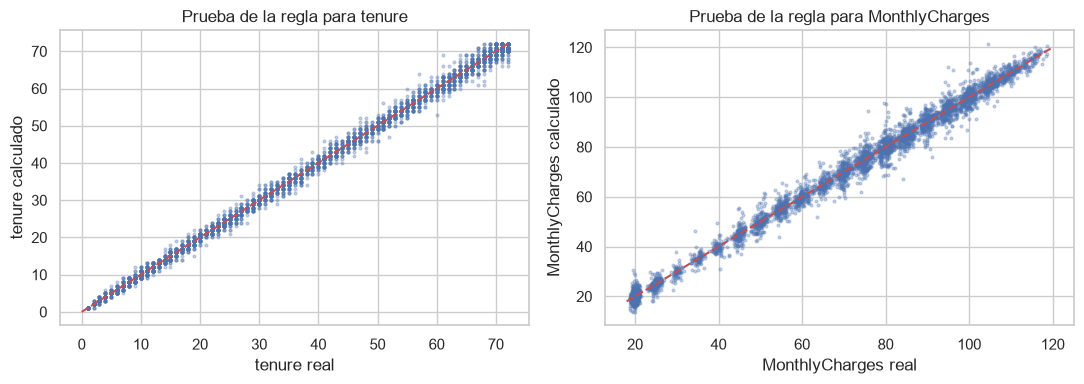

In [5]:
completos = df.dropna(subset=['tenure', 'MonthlyCharges'])
completos = completos[completos['tenure'] > 0]

tenure_calculado = (completos['TotalCharges'] / completos['MonthlyCharges']).round().clip(1, 72)
monthly_calculado = completos['TotalCharges'] / completos['tenure']

error_tenure = abs(tenure_calculado - completos['tenure'])
error_monthly = abs(monthly_calculado - completos['MonthlyCharges'])
print('tenure:  error medio =', round(error_tenure.mean(), 2), 'meses | correlación =',
      round(np.corrcoef(tenure_calculado, completos['tenure'])[0, 1], 4))
print('Monthly: error medio = $', round(error_monthly.mean(), 2), '| correlación =',
      round(np.corrcoef(monthly_calculado, completos['MonthlyCharges'])[0, 1], 4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(completos['tenure'], tenure_calculado, s=4, alpha=0.3)
ax[0].plot([0, 72], [0, 72], 'r--')
ax[0].set_xlabel('tenure real')
ax[0].set_ylabel('tenure calculado')
ax[0].set_title('Prueba de la regla para tenure')
ax[1].scatter(completos['MonthlyCharges'], monthly_calculado, s=4, alpha=0.3)
ax[1].plot([18, 120], [18, 120], 'r--')
ax[1].set_xlabel('MonthlyCharges real')
ax[1].set_ylabel('MonthlyCharges calculado')
ax[1].set_title('Prueba de la regla para MonthlyCharges')
plt.tight_layout()
plt.show()

**Conclusión:** la regla anda muy bien: correlación mayor a 0,99, error medio de menos de 1 mes en tenure y de menos de $2 en el cargo mensual. Es mucho mejor que poner la mediana, que le daría 29 meses a todos cuando el rango va de 0 a 72. La aplicamos:

In [6]:
# tenure = TotalCharges / MonthlyCharges (cuando tenemos los dos y el total es mayor a 0)
filas = df['tenure'].isna() & df['MonthlyCharges'].notna() & (df['TotalCharges'] > 0)
df.loc[filas, 'tenure'] = (df.loc[filas, 'TotalCharges'] / df.loc[filas, 'MonthlyCharges']).round().clip(1, 72)
print('tenure recuperados con la fórmula:', filas.sum())

# si TotalCharges es 0, el cliente es nuevo -> tenure 0
filas = df['tenure'].isna() & (df['TotalCharges'] == 0)
df.loc[filas, 'tenure'] = 0
print('tenure recuperados (cliente nuevo):', filas.sum())

# MonthlyCharges = TotalCharges / tenure (cuando tenure es mayor a 0)
filas = df['MonthlyCharges'].isna() & df['tenure'].notna() & (df['tenure'] > 0)
df.loc[filas, 'MonthlyCharges'] = (df.loc[filas, 'TotalCharges'] / df.loc[filas, 'tenure']).round(2)
print('MonthlyCharges recuperados con la fórmula:', filas.sum())

tenure recuperados con la fórmula: 758
tenure recuperados (cliente nuevo): 1
MonthlyCharges recuperados con la fórmula: 1039


## Paso 4: ¿Cuántos faltantes quedaron?

In [7]:
comparacion = pd.DataFrame()
comparacion['antes'] = faltantes_antes.drop('Unnamed: 0')
comparacion['despues'] = df.isna().sum()
comparacion = comparacion[comparacion['antes'] > 0]
comparacion['% recuperado'] = round((1 - comparacion['despues'] / comparacion['antes']) * 100, 1)
comparacion = comparacion.sort_values('despues', ascending=False)

print('Valores recuperados en total:', comparacion['antes'].sum() - comparacion['despues'].sum())
print('Faltantes:', comparacion['antes'].sum(), '->', comparacion['despues'].sum())
print('Filas completas:', completas_antes, '->', (df.isna().sum(axis=1) == 0).sum(), 'de', len(df))
comparacion

Valores recuperados en total: 3216
Faltantes: 13948 -> 10732
Filas completas: 847 -> 1459 de 7043


,antes,despues,% recuperado
PaymentMethod,1197,1197,0.0
PaperlessBilling,1197,1197,0.0
Contract,1197,1197,0.0
Partner,916,916,0.0
gender,916,916,0.0
SeniorCitizen,916,916,0.0
Dependents,916,916,0.0
MultipleLines,916,841,8.2
OnlineBackup,916,738,19.4
InternetService,916,733,20.0


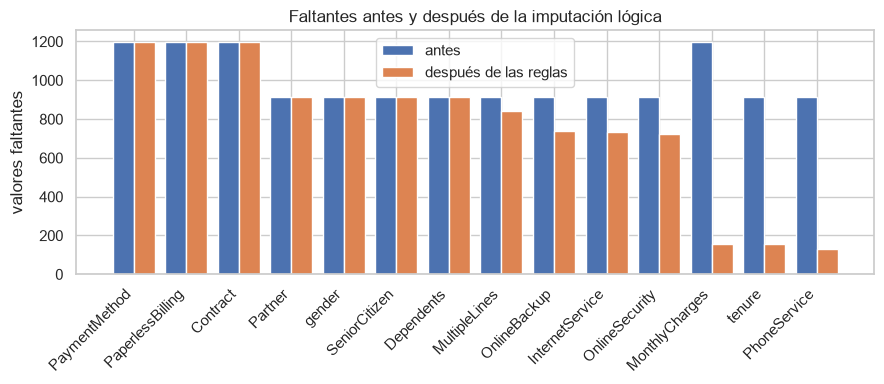

In [8]:
x = np.arange(len(comparacion))
plt.figure(figsize=(9, 4))
plt.bar(x - 0.2, comparacion['antes'], 0.4, label='antes')
plt.bar(x + 0.2, comparacion['despues'], 0.4, label='después de las reglas')
plt.xticks(x, comparacion.index, rotation=45, ha='right')
plt.ylabel('valores faltantes')
plt.title('Faltantes antes y después de la imputación lógica')
plt.legend()
plt.tight_layout()
plt.savefig('figuras/fig5_imputacion.png', dpi=150, bbox_inches='tight')
plt.show()

**Conclusión:** con reglas que no inventan nada recuperamos **3.216 valores (23% de todos los faltantes)**. Lo más importante: recuperamos entre el **83% y el 87%** de los faltantes de `tenure`, `MonthlyCharges` y `PhoneService`. Es justo donde más servía, porque en las numéricas poner la mediana mete mucho ruido. Los clientes con todos los datos pasaron de 847 a 1.459.

Lo que queda (`gender`, `Partner`, `Dependents`, `SeniorCitizen`, `Contract`, `PaperlessBilling`, `PaymentMethod`, la mayor parte de `MultipleLines` y parte de internet y servicios) **no se puede deducir** de otras columnas. Eso lo imputamos en el pipeline del notebook 3:
- con la **mediana** las numéricas
- con la **moda** las categóricas.

Esta imputación se ajusta **solo con train**.

**¿Por qué no imputamos todo acá con la moda?** Porque la moda se calcularía con todos los clientes, incluidos los que después van a ser test. Es data leakage, aunque sea poco.

## Paso 5: Controlamos que todo esté bien y guardamos

In [9]:
# revisamos que las categorías sean las esperadas (que no haya errores de tipeo)
for col in df.columns:
    if col not in ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']:
        print(col, ':', df[col].dropna().unique())

gender : <ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str
SeniorCitizen : <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
Partner : <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents : <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService : <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines : <ArrowStringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService : <ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity : <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup : <ArrowStringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection : <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSupport : <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
StreamingTV : <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
Streaming

In [10]:
# controles: tenure entre 0 y 72, TotalCharges no negativo, Churn solo 0/1 y sin vacíos
print('tenure entre 0 y 72:', df['tenure'].dropna().between(0, 72).all())
print('TotalCharges >= 0:', (df['TotalCharges'] >= 0).all())
print('Churn solo 0 y 1:', df['Churn'].isin([0, 1]).all())

tenure entre 0 y 72: True
TotalCharges >= 0: True
Churn solo 0 y 1: True


In [11]:
df.to_csv('telco_churn_limpio.csv', index=False)
print('Archivo guardado: telco_churn_limpio.csv', df.shape)
df.head()

Archivo guardado: telco_churn_limpio.csv (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,NaN,Yes,No,1.0,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,NaN,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,No,No,No,34.0,Yes,No,NaN,Yes,...,Yes,No,No,No,One year,No,Mailed check,55.57,1889.50,0
2,3668-QPYBK,Male,No,No,No,2.0,Yes,No,NaN,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,No,No,No,44.0,No,No phone service,NaN,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,NaN,NaN,NaN,2.0,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,75.82,151.65,1
